Counts: pre points = 78 | ours points = 709 | front_pre = 5 | front_all = 14 | front_ours = 13


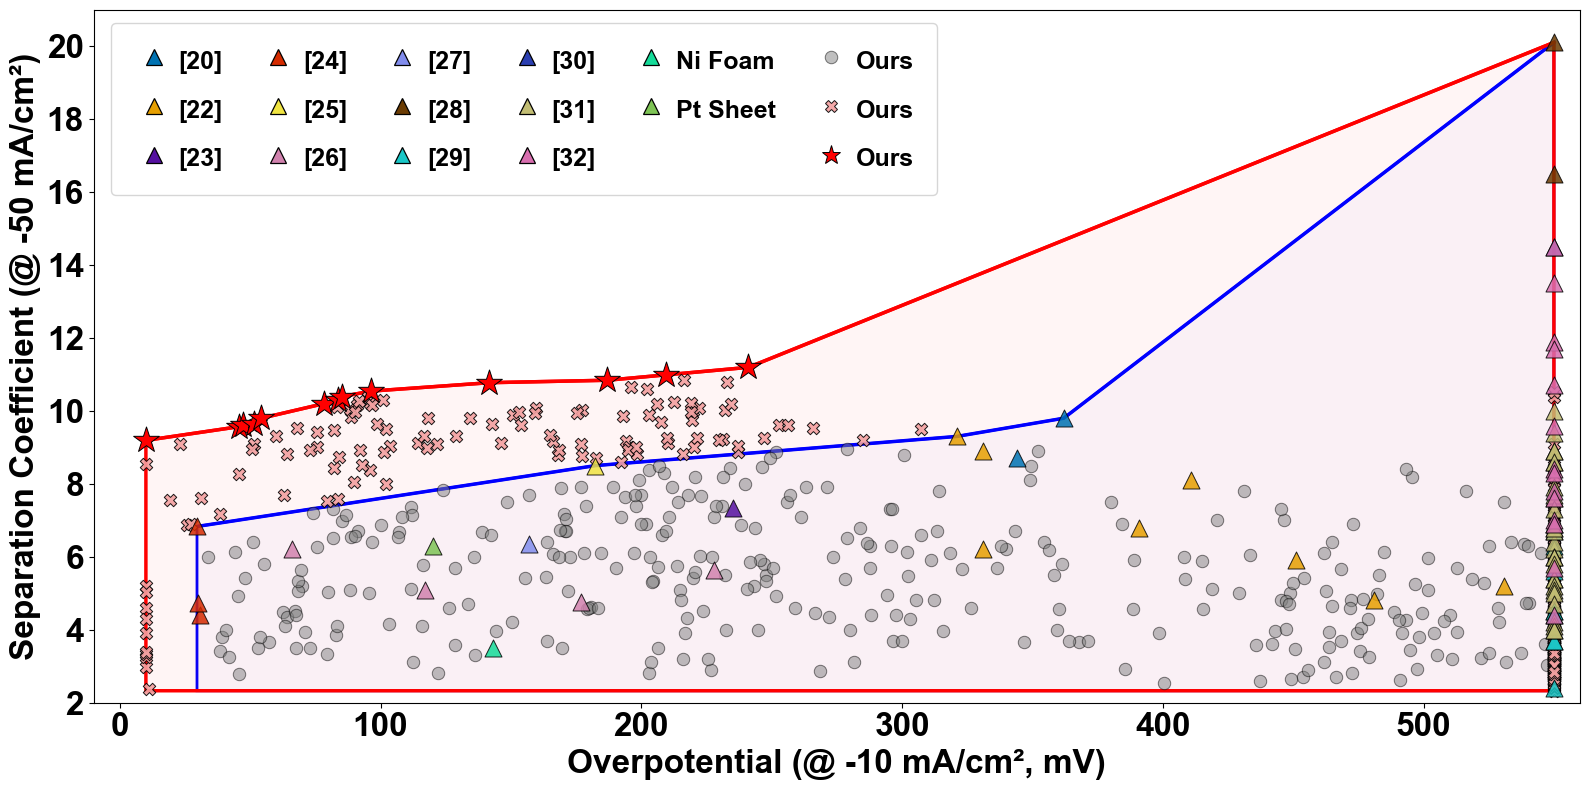

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgba
from matplotlib.path import Path
from matplotlib.ticker import MultipleLocator
import matplotlib as mpl
import re
from matplotlib.lines import Line2D

mpl.rcParams["path.simplify"] = False

# =========================
# Helpers
# =========================
def to_num(s):
    return pd.to_numeric(s, errors="coerce")


def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    if re.match(r"^Reference\s+\d+$", lbl):
        m = re.match(r"^Reference\s+(\d+)$", lbl)
        return f"[{m.group(1)}]" if m else "Literature Report"
    if lbl.lower() == "ni foam":
        return "Ni Foam"
    if lbl.lower() == "pt sheet":
        return "Pt Sheet"
    if lbl.lower() == "this work":
        return "Ours"

    return lbl


def pareto_frontier_xy(pts: pd.DataFrame) -> pd.DataFrame:
    # X lower is better, Y higher is better
    s = pts.sort_values(["x", "y"], ascending=[True, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r["y"] > best_y:
            keep.append(True)
            best_y = r["y"]
        else:
            keep.append(False)
    return s.loc[keep].reset_index(drop=True)


def enclosure_polygon(front: pd.DataFrame, x_ref: float, y_ref: float):
    """
    Build the closed enclosure:
    left-bottom -> left-front-start -> along pareto front
    -> right edge -> bottom edge -> back to left-bottom
    """
    f = front.sort_values("x", ascending=True).reset_index(drop=True)
    x0, y0 = float(f.loc[0, "x"]), float(f.loc[0, "y"])
    y_last = float(f.loc[len(f) - 1, "y"])

    pts = (
        [(x0, y_ref), (x0, y0)]
        + list(map(tuple, f[["x", "y"]].iloc[1:].to_numpy()))
        + [(x_ref, y_last), (x_ref, y_ref)]
    )
    return pts


# =========================
# 1) Load source data
# =========================
from pathlib import Path as FsPath

# Literature/control points are kept in an explicit CSV extracted from the legacy workbook.
# The "This work" points come from the current trusted all_data LSV extraction.
literature_path = FsPath("../data/figure1_bottom_literature_benchmarks.csv")
all_samples_path = FsPath("../data/figure1_bottom_this_work_from_all_data.csv")

lit_points = pd.read_csv(literature_path)
MIN_OVERPOTENTIAL_MV = 10.0
CAP_OVERPOTENTIAL_MV = 550.0

# =========================
# 2) Map each dataset to (x, y) columns
# =========================
# This work is intentionally excluded here and rebuilt from figure1_bottom_this_work_from_all_data.csv.
rows = [
    pd.DataFrame({
        "label": lit_points["source_label"].astype(str),
        "x": to_num(lit_points["plot_x_overpotential_mV"]),
        "y": to_num(lit_points["separation_coefficient"]),
    }).dropna()
]

all_samples = pd.read_csv(all_samples_path)
ours = pd.DataFrame({
    "label": "This work",
    "x": to_num(all_samples["plot_x_overpotential_mV"]),
    "y": to_num(all_samples["separation_coefficient"]),
}).dropna()
rows.append(ours)

data = pd.concat(rows, ignore_index=True)
data = data[np.isfinite(data["x"]) & np.isfinite(data["y"])].copy()
data["x"] = data["x"].clip(lower=MIN_OVERPOTENTIAL_MV, upper=CAP_OVERPOTENTIAL_MV)
data = data.reset_index(drop=True)
data["pid"] = data.index

# Rename numeric refs
data["label"] = data["label"].astype(str).str.strip()
data["label"] = data["label"].apply(lambda s: f"Reference {s}" if s.isdigit() else s)

# =========================
# 3) Split data
# =========================
is_this = data["label"].str.strip().str.lower().eq("this work")

pre = data[~is_this].copy()   # literature + Ni foam + Pt sheet
ours = data[is_this].copy()   # This work only

# Blue Pareto front: literature/control points
front_pre = pareto_frontier_xy(pre)

# Red Pareto front: all data, not only This work
front_all = pareto_frontier_xy(data)

# Only mark This work points that are on the global Pareto frontier
front_ours = front_all[front_all["label"].str.strip().str.lower().eq("this work")].copy()

pareto_ids = set(front_ours["pid"])

print(
    "Counts:",
    "pre points =", len(pre),
    "| ours points =", len(ours),
    "| front_pre =", len(front_pre),
    "| front_all =", len(front_all),
    "| front_ours =", len(front_ours),
)

# =========================
# 4) Build enclosure polygons
# =========================
x_max = float(data["x"].max())
y_min = float(data["y"].min())

x_ref = x_max + 1e-6
y_ref = y_min - 1e-6

# Blue enclosure from literature front
poly_pre = enclosure_polygon(front_pre, 550, y_ref)

# Red enclosure from global front
poly_ours = enclosure_polygon(front_all, x_ref, y_ref)

# =========================
# 5) Plot
# =========================
fig, ax = plt.subplots(figsize=(16, 8))


def label_sort_key(lbl: str):
    lbl = str(lbl)
    if lbl.startswith("Reference "):
        try:
            return (0, int(lbl.split()[-1]))
        except Exception:
            return (0, 10**9)
    if lbl == "Ni foam":
        return (1, 0)
    if lbl == "Pt sheet":
        return (1, 1)
    return (2, lbl)


other_labels = sorted(pre["label"].unique(), key=label_sort_key)

palette = [
    "#0072B2",
    "#E69F00",
    "#5510A0",
    "#D52B00",
    "#F0E442",
    "#D182AE",
    "#818CEC",
    "#6B3C03",
    "#19C7C7",
    "#2B3FB1",
    "#C2BD73",
    "#D86EAF",
    "#15DB99",
    "#7EC455",
]

markers = ["^"]

style = {}
for i, lbl in enumerate(other_labels):
    style[lbl] = dict(
        marker=markers[i % len(markers)],
        color=palette[i % len(palette)]
    )

c_pre = "blue"
c_post = "red"

# Enclosures
ax.add_patch(
    Polygon(
        poly_pre,
        closed=True,
        facecolor=to_rgba(c_pre, 0.02),
        edgecolor=to_rgba(c_pre, 1.0),
        linewidth=2.0,
        zorder=1
    )
)

ax.add_patch(
    Polygon(
        poly_ours,
        closed=True,
        facecolor=to_rgba(c_post, 0.04),
        edgecolor=to_rgba(c_post, 1.0),
        linewidth=2.5,
        zorder=1
    )
)

# Literature points
pre_plot = pre.copy()

for lbl in other_labels:
    sub = pre_plot[pre_plot["label"] == lbl]
    ax.scatter(
        sub["x"], sub["y"],
        s=150,
        alpha=0.85,
        label="_nolegend_",
        zorder=4,
        **style[lbl],
        edgecolors="black",
        linewidths=0.7,
    )

# This work points
thisw = data[is_this].copy()
thisw_nonpareto = thisw[~thisw["pid"].isin(pareto_ids)]

pre_path = Path(poly_pre)
inside_pre = pre_path.contains_points(thisw_nonpareto[["x", "y"]].to_numpy(), radius=1e-9)

ax.scatter(
    thisw_nonpareto.loc[inside_pre, "x"],
    thisw_nonpareto.loc[inside_pre, "y"],
    marker="o",
    s=80,
    color="gray",
    alpha=0.5,
    edgecolors="black",
    linewidths=0.7,
    label="_nolegend_",
    zorder=3
)

ax.scatter(
    thisw_nonpareto.loc[~inside_pre, "x"],
    thisw_nonpareto.loc[~inside_pre, "y"],
    marker="X",
    s=80,
    color="#F3A0A0",
    alpha=0.9,
    edgecolors="black",
    linewidths=0.7,
    label="_nolegend_",
    zorder=3
)

# Pareto front lines
ax.plot(front_pre["x"], front_pre["y"], color=c_pre, linewidth=2.5, zorder=2)
ax.plot(front_all["x"], front_all["y"], color=c_post, linewidth=2.5, zorder=2)

# Pareto stars for This work points on the global frontier
ax.scatter(
    front_ours["x"], front_ours["y"],
    marker="*",
    s=380,
    color="red",
    edgecolors="black",
    linewidths=0.7,
    zorder=10,
    label="_nolegend_"
)

ax.set_ylabel(
    "Separation Coefficient (@ -50 mA/cm²)",
    fontname="Arial",
    fontweight="bold",
    fontsize=24
)
ax.set_xlabel(
    "Overpotential (@ -10 mA/cm², mV)",
    fontname="Arial",
    fontweight="bold",
    fontsize=24
)

ax.yaxis.set_major_locator(MultipleLocator(2))
ax.tick_params(axis="both", which="both", labelsize=24)

for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_fontname("Arial")
    t.set_fontweight("bold")

ax.set_xlim(-10, x_ref + 10)
ax.set_ylim(2, 21)

# =========================
# Custom legend
# =========================
old_leg = ax.get_legend()
if old_leg is not None:
    old_leg.remove()

legend_handles = []
legend_labels = []

# 14 regular entries
for lbl in other_labels:
    pretty_lbl = legend_name(lbl)
    h = Line2D(
        [0], [0],
        marker="^",
        linestyle="None",
        markersize=11,
        markerfacecolor=style[lbl]["color"],
        markeredgecolor="black",
        markeredgewidth=0.9,
        label=pretty_lbl,
    )
    legend_handles.append(h)
    legend_labels.append(pretty_lbl)

# Add 1 blank placeholder so that Ours starts in column 6
blank_handle = Line2D(
    [0], [0],
    linestyle="None",
    marker=None,
    alpha=0.0,
)
legend_handles.append(blank_handle)
legend_labels.append("")

# Ours: inside literature enclosure
h_inside = Line2D(
    [0], [0],
    marker="o",
    linestyle="None",
    markersize=9,
    markerfacecolor="gray",
    markeredgecolor="black",
    markeredgewidth=0.7,
    alpha=0.5,
)

# Ours: outside literature enclosure
h_outside = Line2D(
    [0], [0],
    marker="X",
    linestyle="None",
    markersize=9,
    markerfacecolor="#F3A0A0",
    markeredgecolor="black",
    markeredgewidth=0.7,
    alpha=0.9,
)

# Ours: Pareto front points
h_pareto = Line2D(
    [0], [0],
    marker="*",
    linestyle="None",
    markersize=14,
    markerfacecolor="red",
    markeredgecolor="black",
    markeredgewidth=0.7,
)

legend_handles.extend([h_inside, h_outside, h_pareto])
legend_labels.extend(["Ours", "Ours", "Ours"])

ax.legend(
    handles=legend_handles,
    labels=legend_labels,
    loc="upper left",
    bbox_to_anchor=(0.005, 0.995),
    frameon=True,
    ncol=6,
    columnspacing=1.4,
    handletextpad=0.2,
    borderaxespad=0.4,
    labelspacing=0.8,
    borderpad=0.9,
    handlelength=1.6,
    handleheight=1.4,
    prop={"family": "Arial", "weight": "bold", "size": 18},
)




plt.tight_layout()
fig.savefig("../outputs/pareto_plot_v2.png", dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

